In [19]:
import argparse
import os
from Bio import SeqIO
from Bio.Seq import Seq
import pandas as pd

fasta_path = "../data/SLMQRT_gSES0128_orig_pipeline/blast/SLMQRT_5_5_dnaSES0086.fasta"
blast_path = "../data/SLMQRT_gSES0128_orig_pipeline/blast/RE_blast.tsv"

seq_dict = SeqIO.index(fasta_path, "fasta")

In [39]:
class Args:
    def __init__(self, max_read_size, output):
        self.max_read_size = max_read_size
        self.output = output

args = Args(200, "../data/test.fa")
args.max_read_size

200

,sseqid,sstart,send,sstrand
0,f88f045e-17ff-4a15-819a-334f2968aa9f,1610,1596,minus
1,c09c3499-a7ba-420b-8e97-e41dd9a2c863,5822,5808,minus
2,815b1c20-c981-48ea-9fbf-3367d00ecaea,4179,4165,minus
3,16d8bf5f-eba9-4c25-8fb1-e149f0136dfc,8329,8315,minus
4,f66ce245-c0e2-43f3-8eb6-93c04b60bd03,11530,11516,minus
...,...,...,...,...
520,f59aafa4-ec6f-49bb-8433-f73e4399f901,2165,2179,plus
521,f59aafa4-ec6f-49bb-8433-f73e4399f901,15933,15947,plus
522,cb4caadb-ab1f-4c34-a9b0-14babb0c8c48,8040,8054,plus
523,638059a0-fca2-49ac-8787-48a88b01deef,4756,4770,plus


In [44]:

extracted_seqs = []

for idx, hit in hits.iterrows():
    # Get the full contig length
    contig_len = len(seq_dict[hit["sseqid"]])
    subseq = ""
    boundaries = [hit["sstart"], hit["send"]]
    sstart = min(boundaries)
    send = max(boundaries)

    # --- LOGIC CHANGE START ---
    # Calculate coordinates to get the sequence to the end of the contig.

    if hit["sstrand"].lower() == "plus":
        # On the plus strand, "downstream" is from the hit's end to the contig's end.
        start_pos = send # - 1 + 1 (convert to 0-based, then add 1 so the extracted seq starts outside of the hit)
        end_pos = min(start_pos + args.max_read_size, contig_len)
        
        # Extract sequence only if the hit is not at the very end of the contig
        if start_pos <= contig_len:
            subseq = seq_dict[hit["sseqid"]].seq[start_pos: end_pos]

    else:  # minus strand
        # On the minus strand, "downstream" (towards 3' end) is from the hit's start 
        # towards the beginning of the contig's coordinate system.
        # start_pos = 1
        end_pos = sstart - 1 # Convert to 0-based; this is the actual index of the start pos of the hit BUT won't be included because of exclusive end for slicing
        start_pos = max(end_pos - args.max_read_size, 0)

        # Extract sequence only if the hit is not at the very beginning of the contig
        if end_pos >= 1:
            raw_seq = seq_dict[hit["sseqid"]].seq[start_pos: end_pos]
            subseq = raw_seq.reverse_complement()
    
    if subseq:
        # Create a more descriptive header for each unique extraction
        header = f'hit:{hit["sstart"]}-{send}|strand:{hit["sstrand"]}|downstream_region'
        # out_f.write(f"{header}\n{str(subseq)}\n")
        record = SeqIO.SeqRecord(id=hit["sseqid"], description=header, seq=subseq)
        extracted_seqs.append(record)

with open(args.output, "w") as output_handle:
    SeqIO.write(extracted_seqs, output_handle, "fasta")

In [43]:
from Bio.Seq import Seq

Seq("CGATAACAGTAT").complement()[::-1]

Seq('ATACTGTTATCG')

In [38]:
max([len(record.seq) for record in records])

200

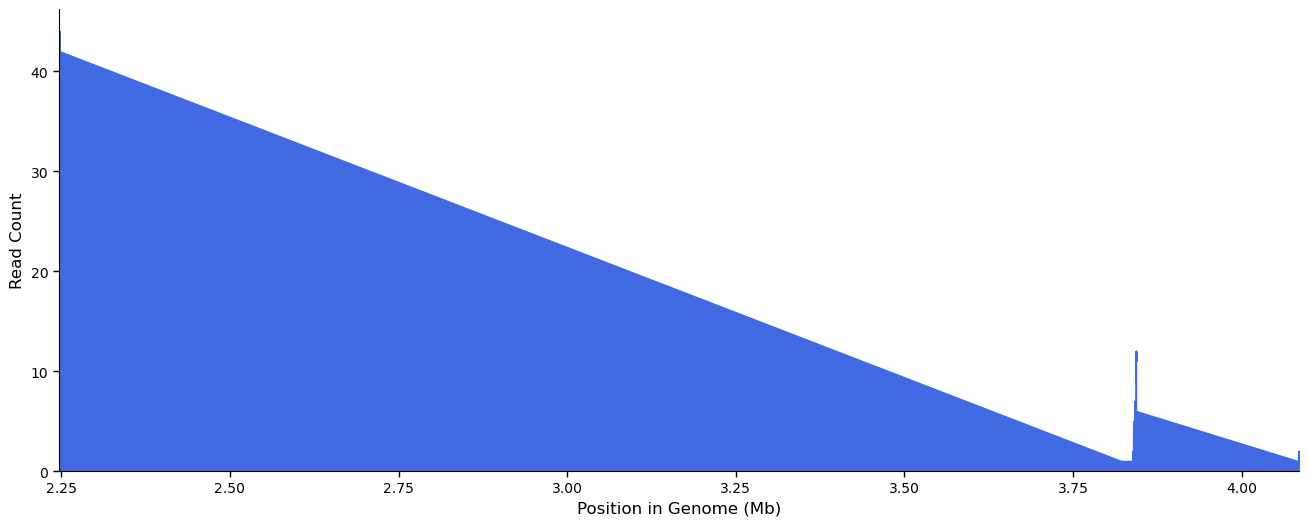

In [13]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns

cov_df = pd.read_csv("/groups/cress/projects/efactors/jack/insertion_mapping/data/SLMQRT_gSES0128/explore/aligned_contigs_depth.tsv", sep="\t", header=None)
cov_df.columns=["chrom", "pos", "depth"]
cov_df["pos_mb"] = cov_df["pos"] / 1_000_000

fig, ax2 = plt.subplots(figsize=(16,6))
ax2.fill_between(cov_df['pos_mb'], cov_df['depth'], color='royalblue')
ax2.set_ylabel("Read Count", fontsize=12)
ax2.set_xlabel("Position in Genome (Mb)", fontsize=12)
ax2.set_ylim(bottom=0)
ax2.set_xlim(cov_df["pos_mb"].min(), cov_df["pos_mb"].max())
ax2.tick_params(
    direction='out',
    length=4,
    width=1,
    colors='black',
    grid_color='none',
    grid_alpha=0.5
)
sns.despine(ax=ax2)


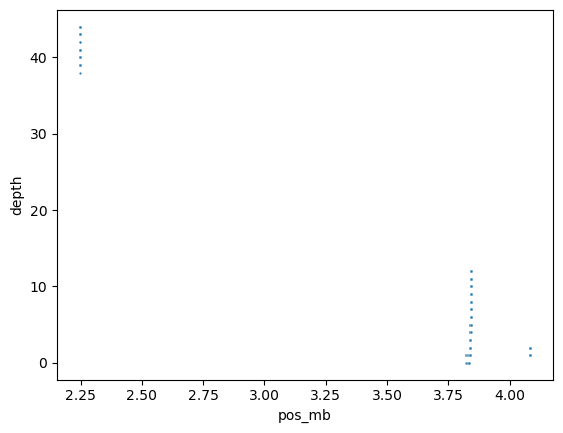

In [18]:
sns.scatterplot(cov_df, x='pos_mb', y='depth', s=2)
plt.show()